# Q14. In which brain area is modularity the lowest? (entire recording)

**Modularity** describes a network. Here the network of each area has:
- **nodes:** its units;
- **links:** how strongly each pair co-fires, measured by STTC at 100 ms over the whole recording (from Q4). Negative values (avoidance) are set to 0.

A network is *modular* if it splits into communities with strong links inside and weak links between them. **Newman's Q** measures how good the best split is. The best split is found with the Louvain algorithm (best of 5 runs).

**Two things can make Q differ between areas without any real communities:**
1. **Network size.** Q depends on the number of nodes, so the subsampled analysis uses the **same number of units per area** (10, or 15 as a check).
2. **The distribution of link weights.** A network whose weights are very uneven reaches a higher Q even when the strong links are placed at random.
   So every Q is compared with the Q of the **same weights shuffled randomly among the links**, which keeps the weights but destroys any community structure.

**Robustness checks:**
- full networks (all units), with a z-score against 30 shuffled versions;
- links from spike-count correlations instead of STTC;
- binary networks keeping only the strongest 20% of links.

The code lives in `c2p/q14_modularity.py`. It was checked on toy networks: two clear communities give Q = 0.42, the same weights shuffled give 0.11, and random weights give 0.03.

In [1]:
import sys; sys.path.insert(0, "..")
import matplotlib.pyplot as plt
import networkx as nx
import numpy as np
import pandas as pd
from networkx.algorithms.community import louvain_communities
from scipy import stats as sps

from c2p import AREAS, AREA_COLORS, RESULTS_DIR
from c2p import q14_modularity as q
from c2p.q04_pairwise import PAIRS_CSV
from c2p.stats import area_bootstrap, per_mouse_tests

sub = q.compute()            # 10/15 units per area, 100 draws (~2 min)
full = q.compute_full()      # all units, 30 null networks (~10 min)
pairs = pd.read_csv(PAIRS_CSV)
print(f"subsampled: {sub[(sub.weights == 'sttc') & (sub.n_units == 10)].mouse.nunique()} mice with ≥10 units in every area; full networks: {full.mouse.nunique()} mice")

subsampled: 18 mice with ≥10 units in every area; full networks: 18 mice


## 1. What the networks look like (one mouse)

Each panel is the STTC link matrix of one area, with units reordered by the communities Louvain found (white lines mark community borders), and its Q.
Below each is the same matrix with the weights shuffled, which gives the Q a random network with these weights would reach.

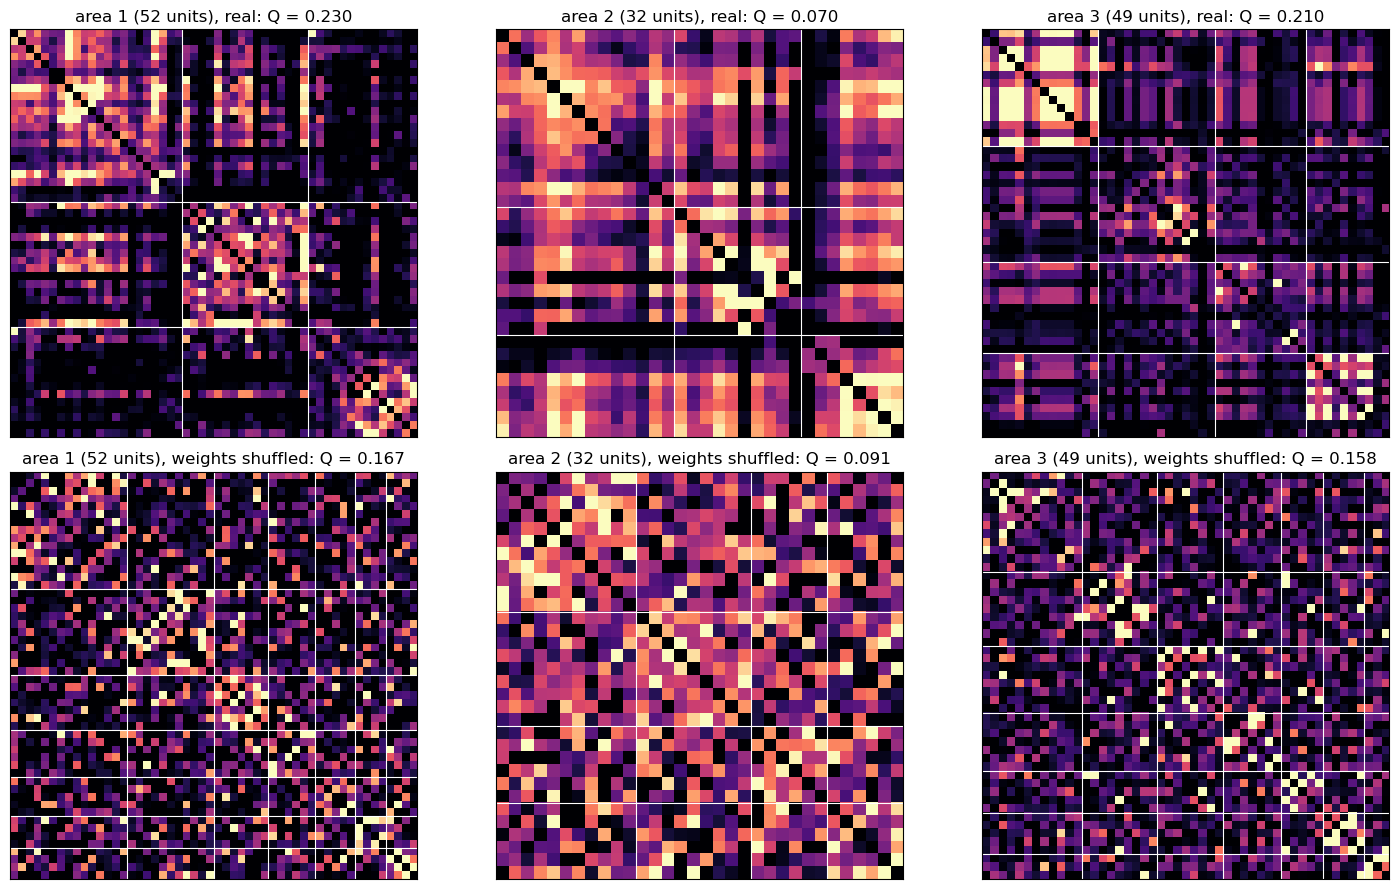

In [2]:
MOUSE = 9
rng = np.random.default_rng(0)
fig, axs = plt.subplots(2, 3, figsize=(15, 9))
for k, a in enumerate(AREAS):
    g = pairs[(pairs.mouse == MOUSE) & (pairs.area == a)]
    units = np.unique(np.r_[g.unit_a, g.unit_b])
    W = q.weight_matrix(g, units, "sttc")
    for row, (M, lab) in enumerate([(W, "real"), (q.permuted(W, rng), "weights shuffled")]):
        comms = louvain_communities(nx.from_numpy_array(M), weight="weight", seed=0)
        order = np.concatenate([sorted(c) for c in sorted(comms, key=len, reverse=True)])
        ax = axs[row, k]
        ax.imshow(M[np.ix_(order, order)], cmap="magma", vmin=0, vmax=np.quantile(W[W > 0], 0.95))
        edges = np.cumsum([len(c) for c in sorted(comms, key=len, reverse=True)])[:-1]
        for e in edges:
            ax.axhline(e - 0.5, color="w", lw=0.8); ax.axvline(e - 0.5, color="w", lw=0.8)
        ax.set(title=f"area {a} ({len(units)} units), {lab}: Q = {q.best_q(M):.3f}", xticks=[], yticks=[])
fig.tight_layout()

## 2. Raw modularity per mouse (full STTC networks)

Friedman p = 1.1e-02


,mice where x > y,n mice,wilcoxon p
pair,,,
area 1 vs area 2,6,18,0.2837
area 1 vs area 3,3,18,0.0016
area 2 vs area 3,6,18,0.0342


The shuffled networks show the same ranking: much of the raw difference comes from the weight distribution.


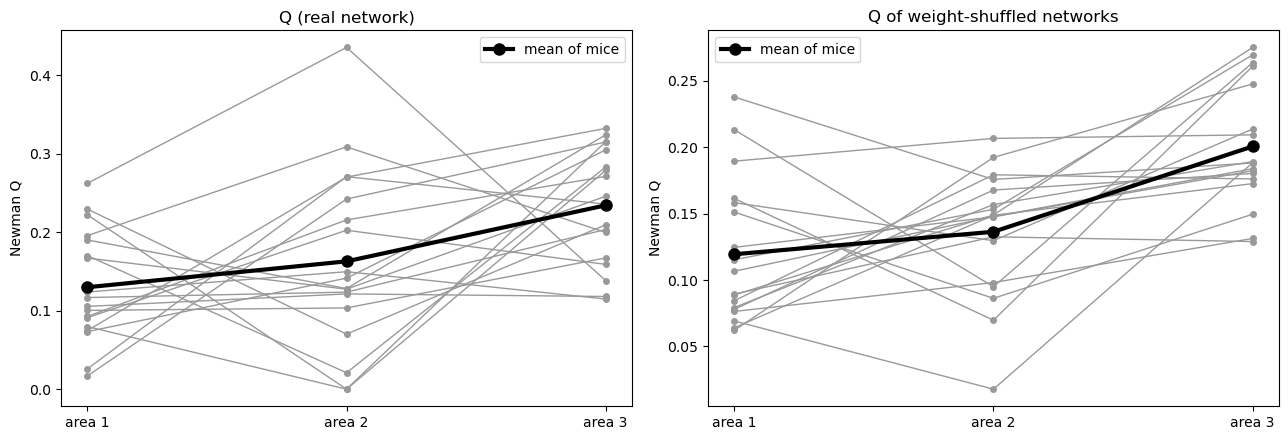

In [3]:
fw = full[(full.weights == "sttc") & (full.network == "weighted")]
per_mouse, friedman, wilc = per_mouse_tests(fw, "Q")
nulls = fw.pivot(index="mouse", columns="area", values="Q_null")
fig, axs = plt.subplots(1, 2, figsize=(13, 4.5))
for ax, (t, lab) in zip(axs, [(per_mouse, "Q (real network)"), (nulls, "Q of weight-shuffled networks")]):
    for m, row in t.iterrows():
        ax.plot(AREAS, row.values, "-o", color="0.6", ms=4, lw=1)
    ax.plot(AREAS, t.mean().values, "-o", color="k", lw=3, ms=8, label="mean of mice")
    ax.set(xticks=AREAS, xticklabels=[f"area {a}" for a in AREAS], ylabel="Newman Q", title=lab); ax.legend()
fig.tight_layout()
print("Friedman p =", f"{friedman.pvalue:.1e}")
display(wilc.round(4))
print("The shuffled networks show the same ranking: much of the raw difference comes from the weight distribution.")

## 3. Beyond chance: real Q compared with weight-shuffled networks

z = (Q − mean of the shuffled networks) / their SD, per mouse and area. Around 0 means no more community structure than chance.

Friedman p = 0.85


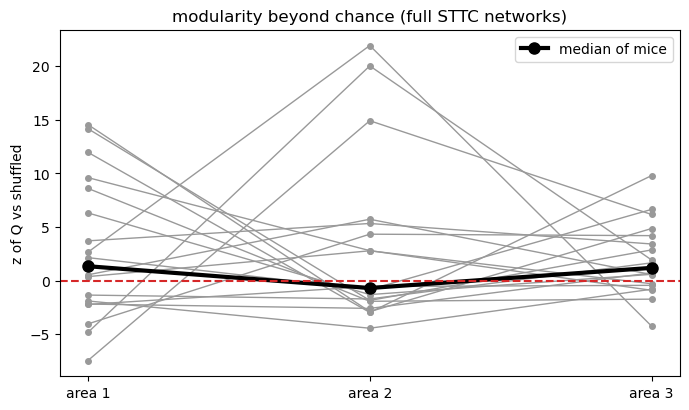

In [4]:
fig, ax = plt.subplots(figsize=(8, 4.5))
zt = fw.pivot(index="mouse", columns="area", values="z")
for m, row in zt.iterrows():
    ax.plot(AREAS, row.values, "-o", color="0.6", ms=4, lw=1)
ax.plot(AREAS, zt.median().values, "-o", color="k", lw=3, ms=8, label="median of mice")
ax.axhline(0, color="tab:red", ls="--")
ax.set(xticks=AREAS, xticklabels=[f"area {a}" for a in AREAS], ylabel="z of Q vs shuffled", title="modularity beyond chance (full STTC networks)")
ax.legend()
print("Friedman p =", f"{sps.friedmanchisquare(*[zt[a] for a in AREAS]).pvalue:.2f}")

## 4. All variants

In [5]:
def summ(t):
    t = t.dropna()
    w = {f"{x} vs {y}": sps.wilcoxon(t[x], t[y]).pvalue for x, y in [(1, 2), (1, 3), (2, 3)]}
    return {**{f"area {a}": t[a].mean() for a in AREAS}, "mice": len(t), "lowest (mean)": f"area {t.mean().idxmin()}",
            "lowest in n mice": dict(t.idxmin(axis=1).value_counts().sort_index()),
            "Friedman p": sps.friedmanchisquare(*[t[a] for a in AREAS]).pvalue, **{f"Wilcoxon {k}": v for k, v in w.items()}}

rows = {}
for (w_, net), g in full.groupby(["weights", "network"]):
    for col in ["Q", "z"]:
        rows[f"full, {w_}, {net}, {col}"] = summ(g.pivot(index="mouse", columns="area", values=col))
for (w_, n), g in sub.groupby(["weights", "n_units"]):
    for col in ["Q", "Q_minus_null"]:
        rows[f"{n} units, {w_}, weighted, {col}"] = summ(g.pivot(index="mouse", columns="area", values=col))
robust = pd.DataFrame(rows).T
robust

,area 1,area 2,area 3,mice,lowest (mean),lowest in n mice,Friedman p,Wilcoxon 1 vs 2,Wilcoxon 1 vs 3,Wilcoxon 2 vs 3
"full, count_corr, binary top 20%, Q",0.267981,0.231862,0.252619,18,area 2,"{1: 4, 2: 9, 3: 5}",0.606531,0.392738,0.495079,0.495079
"full, count_corr, binary top 20%, z",0.533404,-0.679124,-1.75647,18,area 3,"{1: 4, 2: 8, 3: 6}",0.311403,0.369217,0.154045,0.865044
"full, count_corr, weighted, Q",0.145859,0.164681,0.205412,18,area 1,"{1: 7, 2: 7, 3: 4}",0.311403,0.670525,0.066536,0.167351
"full, count_corr, weighted, z",4.888152,2.280326,-0.295278,18,area 3,"{1: 3, 2: 8, 3: 7}",0.055638,0.264526,0.0056,0.579842
"full, sttc, binary top 20%, Q",0.240621,0.244336,0.315874,18,area 1,"{1: 8, 2: 8, 3: 2}",0.128022,1.0,0.030365,0.053856
"full, sttc, binary top 20%, z",-1.175522,-0.14317,-0.302544,18,area 1,"{1: 8, 2: 7, 3: 3}",0.67781,0.932281,0.468292,0.639694
"full, sttc, weighted, Q",0.129902,0.162921,0.234299,18,area 1,"{1: 10, 2: 6, 3: 2}",0.011109,0.28373,0.001579,0.034233
"full, sttc, weighted, z",2.81986,3.15938,1.949615,18,area 3,"{1: 5, 2: 9, 3: 4}",0.846482,0.898575,0.701881,1.0
"10 units, count_corr, weighted, Q",0.124488,0.158424,0.173767,14,area 1,"{1: 6, 2: 5, 3: 3}",0.606531,0.241211,0.357544,0.390991
"10 units, count_corr, weighted, Q_minus_null",-0.01891,-0.027201,-0.044782,14,area 3,"{1: 2, 2: 4, 3: 8}",0.22313,0.357544,0.172607,0.501587


## 5. Answer for the questionnaire

**Not enough data / no differences.**
- With raw weighted STTC modularity, area 1 has the lowest Q, but it is not significantly lower than area 2 in any variant.
- With count-correlation links or binary networks, raw Q doesn't differ between areas.
- Once Q is compared with weight-shuffled networks, no area differs in any variant. The raw ranking follows how uneven each area's link weights are, not community structure.

In [6]:
from c2p.questionnaire import fill_pdf, record_answer, record_meta

t_main, _ = area_bootstrap(fw, "Q")
rows_q = [(f"{t_main.loc[f'area {a}', 'estimate']:.3f}", f"[{t_main.loc[f'area {a}', 'ci_low']:.3f}, {t_main.loc[f'area {a}', 'ci_high']:.3f}]",
           "Newman Q") for a in AREAS]
t_main.to_csv(RESULTS_DIR / "q14_answer.csv")
m = t_main.estimate
z_p = sps.friedmanchisquare(*[zt[a] for a in AREAS]).pvalue
expl = (
    f"For each area I built a functional network over the whole recording: units as nodes and pairwise spike time tiling "
    f"coefficients (100 ms) as link weights, negative values set to 0. Modularity was Newman's Q of the best Louvain "
    f"partition. The table gives Q of the full networks, mean over mice with a bootstrap CI over mice. Area 1 had the lowest raw Q ({m['area 1']:.3f} vs {m['area 2']:.3f} in area 2 and {m['area 3']:.3f} in area 3), "
    f"lower than area 3 (Wilcoxon p = {wilc.loc['area 1 vs area 3', 'wilcoxon p']:.3f}) but not than area 2 "
    f"(p = {wilc.loc['area 1 vs area 2', 'wilcoxon p']:.2f}). Because Q depends on network size and on the weight "
    f"distribution, I compared each network with versions whose weights were shuffled among links, and repeated the "
    f"analysis with equal-size subsamples (10 and 15 units), count-correlation links and binary networks of the strongest "
    f"20% of links. The shuffled networks reproduced the raw ranking, Q did not exceed the shuffled networks differently "
    f"between areas (Friedman p = {z_p:.2f}), and area 1 was never significantly lower than area 2. I therefore found no "
    f"reliable difference in modularity between areas."
)
print(len(expl.split()), "words"); print(expl)
record_answer(14, choice=3, rows=rows_q, explanation=expl)  # 3 = not enough data / no differences
record_meta(14, confidence=4, consensus=3)
print(fill_pdf())

177 words
For each area I built a functional network over the whole recording: units as nodes and pairwise spike time tiling coefficients (100 ms) as link weights, negative values set to 0. Modularity was Newman's Q of the best Louvain partition. The table gives Q of the full networks, mean over mice with a bootstrap CI over mice. Area 1 had the lowest raw Q (0.130 vs 0.163 in area 2 and 0.234 in area 3), lower than area 3 (Wilcoxon p = 0.002) but not than area 2 (p = 0.28). Because Q depends on network size and on the weight distribution, I compared each network with versions whose weights were shuffled among links, and repeated the analysis with equal-size subsamples (10 and 15 units), count-correlation links and binary networks of the strongest 20% of links. The shuffled networks reproduced the raw ranking, Q did not exceed the shuffled networks differently between areas (Friedman p = 0.85), and area 1 was never significantly lower than area 2. I therefore found no reliable differen

/home/dariosannino/con2phys/docs/questionnaire_filled.pdf
